# C. MiniRocket 기준선 — 녹화 하나 빼기 21-fold

- 할 일: IMU 진동 구간 하나(128스텝 × 6채널)를 보고 바닥 재질 8종 중 하나를 맞힌다
- 이 노트북의 역할: C 파트 딥러닝 모델(FCN·LSTM)이 넘어야 할 시계열 기준선
  - MiniRocket(Dempster et al., 2021, KDD): 시계열 분류에서 학습이 빠르고 정확도가 높아 표준 비교 대상으로 쓰는 모델
- 평가: `splits/folds.json`의 녹화 하나 빼기 21-fold → 21개 fold 예측을 모두 모은 뒤 `evaluate()` 한 번
- 기록: 수치는 `results/results.csv`, 걸린 시간·설정은 프로젝트 진행 기록

실행: Colab에서 위에서부터 차례로 실행 (런타임은 CPU로 충분, GPU 필요 없음)

## 0. 환경 준비

- Colab이면 레포를 받고, 패키지를 설치하고, Zenodo에서 데이터(약 78MB)를 받는다
- `aeon`: MiniRocket이 들어 있는 시계열 라이브러리 (1.6 이상 기준으로 작성)
- 설치 뒤 "런타임 다시 시작" 안내가 뜨면 다시 시작하고 이 셀부터 다시 실행 (이미 받은 건 건너뜀)

In [ ]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/ML-imu").exists():
        !git clone -q https://github.com/ekgP525/ML-imu.git /content/ML-imu
    os.chdir("/content/ML-imu")
    # aeon이 쓰는 numba는 NumPy 2.3까지만 지원한다 → numpy를 2.4 미만으로 맞춘다
    !pip install -q -r requirements.txt "aeon>=1.6,<2" "numpy<2.4"
    import importlib.metadata
    if "numpy" in sys.modules and sys.modules["numpy"].__version__ != importlib.metadata.version("numpy"):
        raise RuntimeError("numpy 버전이 바뀌었어요. 런타임 → 세션 다시 시작 후 맨 위부터 다시 실행하세요.")
    !python data/download.py

# 레포 루트(src/가 있는 폴더)를 찾아 공통 코드를 불러올 수 있게 한다
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
print("레포 위치:", ROOT)

download label.npy
download details.csv
download X_data.npy
download groups.npy
레포 위치: /content/ML-imu


## 1. 데이터 불러오기

`load_dataset()`(A가 만든 공통 코드)이 돌려주는 것:

- `X`: (7626, 128, 6) — 구간 7,626개 × 시간 128스텝 × 채널 6개
  - 채널: 각속도 3개(gyro_x·y·z) + 선가속도 3개(acc_x·y·z)
  - 방향(쿼터니언) 4채널은 뺐다. 녹화마다 값이 거의 고정이라 재질이 아니라 "어느 녹화인지"를 알려 주는 누수 정보가 되기 때문
- `y`: 구간마다 재질 이름 8종 (hard_tiles + hard_tiles_large_space는 하나로 합침)
- `rec`: 구간마다 녹화 번호 0~20. 원래 80개 그룹은 연속 녹화 21개를 잘라 놓은 것이라 A가 다시 이어 붙였다

아래 표가 README 표(carpet 869구간·녹화 3개 …)와 같으면 정상

In [ ]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recordings import load_dataset, summary, CLASSES, CHANNEL_NAMES
from splits import load_folds, fold_indices
from preprocess import normalize
from evaluate import evaluate, log_result, to_mode

SEED = 42

X, y, rec = load_dataset(str(ROOT / "data"))
print("X:", X.shape, X.dtype)
print("채널:", CHANNEL_NAMES)
summary(y, rec)

X: (7626, 128, 6) float32
채널: ['gyro_x', 'gyro_y', 'gyro_z', 'acc_x', 'acc_y', 'acc_z']


,segments,recordings,mode
surface,,,
carpet,869,3,carpet
concrete,1057,3,hard
fine_concrete,821,2,hard
hard_tiles,879,2,hard
soft_pvc,1176,4,soft
soft_tiles,522,2,soft
tiled,1267,3,hard
wood,1035,2,hard


## 2. 분할 확인 — 왜 "녹화 하나 빼기"인가

- 같은 녹화에서 나온 구간끼리는 센서 위치·속도·바닥 상태가 같아서 아주 비슷하다
- 구간을 무작위로 섞어 나누면, 시험 구간의 "형제" 구간이 학습에 들어가 있어서 정확도가 부풀려진다 (커닝)
- 그래서 fold마다 녹화 1개를 통째로 시험용으로 빼고, 나머지 20개로 학습한다 → 21번 반복
  - 실제 상황("처음 가 본 집의 바닥")과 같은 조건
- 주의: fold마다 시험 녹화는 재질 1종뿐이라 fold별 macro-F1은 의미가 없다. 21개 fold 예측을 모아서 한 번에 평가한다
- 재질마다 녹화가 2~4개뿐이다. 예를 들어 wood(녹화 2개)는 하나를 시험으로 빼면 학습에 wood 녹화가 1개만 남는다 → 어려운 fold

In [ ]:
folds = load_folds()
print("fold 수:", len(folds))

rec_info = (pd.DataFrame({"recording": rec, "surface": y})
            .groupby("recording")
            .agg(surface=("surface", "first"), segments=("surface", "size")))
display(rec_info.T)

tr, te = fold_indices(folds[0], rec)
print(f"fold 0: 학습 {len(tr)}구간(녹화 {len(folds[0]['train'])}개), "
      f"시험 {len(te)}구간(녹화 {folds[0]['test']} = {y[te][0]})")

fold 수: 21


recording,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
surface,hard_tiles,soft_pvc,soft_tiles,fine_concrete,concrete,soft_pvc,hard_tiles,carpet,tiled,fine_concrete,...,soft_tiles,tiled,soft_pvc,wood,carpet,concrete,tiled,wood,concrete,carpet
segments,303,362,287,243,219,404,576,172,273,578,...,235,457,277,129,366,478,537,906,360,331


fold 0: 학습 7323구간(녹화 20개), 시험 303구간(녹화 [0] = hard_tiles)


## 3. MiniRocket 모델 구조

세 단계로 된 파이프라인이다. 학습되는 건 마지막 선형 분류기뿐이라 빠르다.

1. **MiniRocket 특성 변환** (학습 없음, 정해진 필터)
   - 길이 9짜리 작은 필터 84개. 가중치가 -1과 2로만 되어 있는 정해진 패턴 (9칸 중 3칸이 2)
   - dilation(필터 칸 사이 간격)을 여러 개 써서 짧은 진동 패턴부터 긴 패턴까지 본다
   - 필터마다 채널 몇 개를 무작위로 골라 함께 본다 (다채널 입력 처리)
   - 문턱값(bias)은 학습 데이터에서 뽑는다 → 그래서 변환도 학습 녹화로만 `fit` 해야 한다
   - 특성 값 = PPV: 필터 출력이 문턱값보다 큰 시간 비율(0~1). "이 패턴이 신호에 얼마나 자주 나오나"
   - 필터 × dilation × 문턱값 조합으로 구간 하나가 숫자 약 10,000개(정확히는 84의 배수 9,996개)가 된다
2. **표준화** (`StandardScaler(with_mean=False)`): 특성마다 크기를 맞춘다
3. **Ridge 선형 분류기** (`RidgeClassifierCV`)
   - L2 정규화(가중치 제곱합 벌점)를 건 선형 모델. 특성이 1만 개라 과적합을 막는 벌점 세기 alpha가 중요
   - alpha 후보 10개(0.001~1000) 중 학습 데이터 안에서 하나씩 빼 보기(LOO)로 자동 선택

aeon의 `MiniRocketClassifier`와 같은 구성(원 논문 설정)이다. 단계를 나눠 쓴 건 구조를 보이고 나중에 변환만 바꿔 끼우기 위해서다.

In [ ]:
import aeon
from aeon.transformations.collection.convolution_based import MiniRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print("aeon", aeon.__version__, "| CPU", os.cpu_count(), "개")


def make_minirocket():
    return make_pipeline(
        MiniRocket(n_kernels=10_000, random_state=SEED, n_jobs=-1),
        StandardScaler(with_mean=False),
        RidgeClassifierCV(alphas=np.logspace(-3, 3, 10)),
    )

aeon 1.6.0 | CPU 2 개


## 4. 21-fold 실행

fold마다 하는 일:

1. `fold_indices()`로 학습·시험 구간 번호를 받는다
2. 정규화: 학습 녹화의 채널별 평균·표준편차만으로 학습·시험을 같이 정규화 (시험 정보 누수 금지)
3. 모양 바꾸기: aeon은 (구간 수, 채널 수, 시간) 순서를 받으므로 (N, 128, 6) → (N, 6, 128)
4. 학습 → 시험 녹화 예측 → 전체 예측 배열의 해당 자리에 채움

- 첫 fold는 numba 컴파일 때문에 더 오래 걸린다. 시간 기록 때는 평균과 따로 적는다

In [ ]:
def run_cv(make_model, name):
    y_pred = np.empty(len(y), dtype=object)
    rows = []
    t_all = time.perf_counter()
    for fold in folds:
        tr, te = fold_indices(fold, rec)
        t0 = time.perf_counter()

        X_tr, stats = normalize(X[tr])          # 학습 녹화로 통계 계산
        X_te = normalize(X[te], stats)          # 같은 통계로 시험 정규화
        # (N, 128, 6) → (N, 6, 128), 메모리에 연속으로 놓이게 복사
        X_tr = np.ascontiguousarray(X_tr.transpose(0, 2, 1), dtype=np.float32)
        X_te = np.ascontiguousarray(X_te.transpose(0, 2, 1), dtype=np.float32)

        model = make_model().fit(X_tr, y[tr])
        y_pred[te] = model.predict(X_te)

        sec = time.perf_counter() - t0
        acc = float(np.mean(y_pred[te] == y[te]))
        wrong = pd.Series(y_pred[te][y_pred[te] != y[te]])
        rows.append({
            "fold": fold["fold"],
            "test_rec": fold["test"][0],
            "surface": y[te][0],
            "segments": len(te),
            "accuracy": round(acc, 3),
            "mostly_confused_with": wrong.mode().iloc[0] if len(wrong) else "-",
            "alpha": float(model[-1].alpha_),
            "sec": round(sec, 1),
        })
        print(f"[{name}] fold {fold['fold']:2d} | 녹화 {fold['test'][0]:2d} {y[te][0]:<13} "
              f"| 정확도 {acc:.3f} | {sec:5.1f}초")

    total = time.perf_counter() - t_all
    assert not any(p is None for p in y_pred), "예측이 비어 있는 구간이 있음"
    print(f"[{name}] 전체 {total:.0f}초")
    return y_pred.astype(str), pd.DataFrame(rows), total


y_pred_mr, per_fold_mr, sec_mr = run_cv(make_minirocket, "minirocket")
per_fold_mr

[minirocket] fold  0 | 녹화  0 hard_tiles    | 정확도 0.304 | 196.7초
[minirocket] fold  1 | 녹화  1 soft_pvc      | 정확도 0.514 | 150.3초
[minirocket] fold  2 | 녹화  2 soft_tiles    | 정확도 0.021 | 155.9초
[minirocket] fold  3 | 녹화  3 fine_concrete | 정확도 0.148 | 156.3초
[minirocket] fold  4 | 녹화  4 concrete      | 정확도 0.297 | 159.2초
[minirocket] fold  5 | 녹화  5 soft_pvc      | 정확도 0.015 | 151.0초
[minirocket] fold  6 | 녹화  6 hard_tiles    | 정확도 0.094 | 140.5초
[minirocket] fold  7 | 녹화  7 carpet        | 정확도 0.669 | 160.3초
[minirocket] fold  8 | 녹화  8 tiled         | 정확도 0.011 | 153.8초
[minirocket] fold  9 | 녹화  9 fine_concrete | 정확도 0.005 | 140.8초
[minirocket] fold 10 | 녹화 10 soft_pvc      | 정확도 0.752 | 162.4초
[minirocket] fold 11 | 녹화 11 soft_tiles    | 정확도 0.013 | 155.9초
[minirocket] fold 12 | 녹화 12 tiled         | 정확도 0.530 | 148.8초
[minirocket] fold 13 | 녹화 13 soft_pvc      | 정확도 0.466 | 154.4초
[minirocket] fold 14 | 녹화 14 wood          | 정확도 0.535 | 163.9초
[minirocket] fold 15 | 녹화 15 carpet     

,fold,test_rec,surface,segments,accuracy,mostly_confused_with,alpha,sec
0,0,0,hard_tiles,303,0.304,tiled,1000.0,196.7
1,1,1,soft_pvc,362,0.514,wood,1000.0,150.3
2,2,2,soft_tiles,287,0.021,soft_pvc,1000.0,155.9
3,3,3,fine_concrete,243,0.148,concrete,1000.0,156.3
4,4,4,concrete,219,0.297,hard_tiles,1000.0,159.2
5,5,5,soft_pvc,404,0.015,soft_tiles,1000.0,151.0
6,6,6,hard_tiles,576,0.094,tiled,1000.0,140.5
7,7,7,carpet,172,0.669,wood,1000.0,160.3
8,8,8,tiled,273,0.011,fine_concrete,1000.0,153.8
9,9,9,fine_concrete,578,0.005,concrete,1000.0,140.8


## 5. 전체 결과

- **macro-F1**: 재질 8종 각각의 F1을 낸 뒤 단순 평균. 구간이 적은 재질(soft_tiles 522개)도 많은 재질과 같은 무게 → 팀 주 지표
- **정확도**: 맞힌 구간 비율. 구간이 많은 재질 성적에 끌려간다
- **모드 macro-F1 / 모드 정확도**: 재질을 청소 모드 3종(카펫·부드러운·딱딱한)으로 바꿔서 채점
  - 비교 기준: 전부 "딱딱한 바닥"으로 찍어도 모드 정확도 66.3%. 이걸 못 넘으면 모드 전환에 쓸모가 없다

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

metrics = evaluate(y, y_pred_mr)
mode_acc = float(np.mean(to_mode(y) == to_mode(y_pred_mr)))
print({k: round(float(v), 4) for k, v in metrics.items()})
print(f"모드 정확도 {mode_acc:.3f}  (전부 '딱딱한 바닥'으로 찍으면 0.663)")
print()
print(classification_report(y, y_pred_mr, labels=CLASSES, digits=3, zero_division=0))

{'macro_f1': 0.2571, 'accuracy': 0.2796, 'mode_macro_f1': 0.7163}
모드 정확도 0.756  (전부 '딱딱한 바닥'으로 찍으면 0.663)

               precision    recall  f1-score   support

       carpet      0.682     0.846     0.755       869
     concrete      0.292     0.279     0.286      1057
fine_concrete      0.042     0.048     0.044       821
   hard_tiles      0.195     0.166     0.180       879
     soft_pvc      0.330     0.358     0.344      1176
   soft_tiles      0.013     0.017     0.015       522
        tiled      0.287     0.289     0.288      1267
         wood      0.195     0.117     0.146      1035

     accuracy                          0.280      7626
    macro avg      0.255     0.265     0.257      7626
 weighted avg      0.271     0.280     0.273      7626



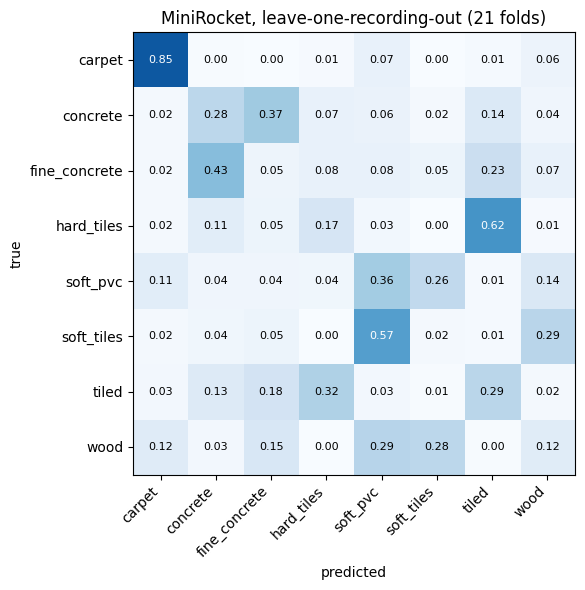

In [ ]:
# 혼동행렬: 행 = 정답, 열 = 예측, 행마다 비율(정답 재질 중 몇 %를 무엇으로 예측했나)
cm = confusion_matrix(y, y_pred_mr, labels=CLASSES, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("MiniRocket, leave-one-recording-out (21 folds)")
plt.tight_layout()
plt.show()

### 결과 읽는 법

- fold 표(4번 셀 출력)에서 정확도가 0에 가까운 녹화: 같은 재질의 다른 녹화와 신호가 많이 다르다는 뜻. 어떤 재질로 헷갈렸는지(`mostly_confused_with`)를 같이 본다
- 혼동행렬에서 대각선 밖 큰 칸: 서로 헷갈리는 재질 쌍. 같은 모드 안(예: concrete ↔ tiled)에서 헷갈리면 청소에는 영향이 적고, 모드가 다르면(예: wood ↔ carpet) 문제가 크다
- `alpha`가 후보 끝값(0.001 또는 1000)에 붙어 있으면 후보 범위가 좁다는 신호
- 한계: alpha는 학습 구간 안에서 하나씩 빼 보기로 고른다. 같은 녹화 구간끼리 비슷해서 이 점수가 낙관적일 수 있다 → 검증 녹화(`inner_val_recordings`)로 고르는 것과 나중에 비교해 볼 만하다

## 6. 결과 기록

- `log_result()`가 `results/results.csv`에 한 줄을 추가한다
- Colab의 레포는 임시 복사본이다. 출력된 마지막 줄을 로컬 레포 `results/results.csv`에 붙여 넣고 커밋한다

In [ ]:
note = f"aeon MiniRocket 9996 features + Ridge, 6ch, train-rec norm, total {sec_mr:.0f}s"
log_result("C", "minirocket", metrics, setting="8class", fold="all", note=note)
print((ROOT / "results" / "results.csv").read_text(encoding="utf-8"))

print("진행 기록용 --------------------------------")
print(f"aeon {aeon.__version__}, CPU {os.cpu_count()}개")
print(f"21-fold 전체 {sec_mr:.0f}초, fold 평균 {per_fold_mr.sec.mean():.1f}초, "
      f"첫 fold {per_fold_mr.sec.iloc[0]:.1f}초(numba 컴파일 포함)")
print(f"선택된 alpha: {per_fold_mr.alpha.value_counts().to_dict()}")

date,owner,model,setting,fold,macro_f1,accuracy,mode_macro_f1,auroc,fpr95,note
2026-11-23,C,minirocket,8class,all,0.2571,0.2796,0.7163,,,"aeon MiniRocket 9996 features + Ridge, 6ch, train-rec norm, total 3235s"

진행 기록용 --------------------------------
aeon 1.6.0, CPU 2개
21-fold 전체 3235초, fold 평균 154.0초, 첫 fold 196.7초(numba 컴파일 포함)
선택된 alpha: {1000.0: 21}


## 7. (선택) MultiRocket — 같은 계열의 더 새로운 모델

- MultiRocket(Tan et al., 2022): MiniRocket에 원신호의 1차 차분(변화량)을 추가로 보고, 특성 종류를 PPV 1개에서 4개로 늘린 모델
- 바꾸는 건 변환 한 줄뿐. 특성 수가 MiniRocket의 약 5배라 메모리와 시간이 더 든다
- 실행하려면 `RUN_MULTIROCKET = True`

In [ ]:
RUN_MULTIROCKET = False

if RUN_MULTIROCKET:
    from aeon.transformations.collection.convolution_based import MultiRocket

    def make_multirocket():
        return make_pipeline(
            MultiRocket(n_kernels=6_250, random_state=SEED, n_jobs=-1),
            StandardScaler(with_mean=False),
            RidgeClassifierCV(alphas=np.logspace(-3, 3, 10)),
        )

    y_pred_mu, per_fold_mu, sec_mu = run_cv(make_multirocket, "multirocket")
    metrics_mu = evaluate(y, y_pred_mu)
    print({k: round(float(v), 4) for k, v in metrics_mu.items()})
    log_result("C", "multirocket", metrics_mu, setting="8class", fold="all",
               note=f"aeon MultiRocket 6250 kernels + Ridge, 6ch, total {sec_mu:.0f}s")

## 메모할 것

- 모델·설정: MiniRocket 10,000 kernels(실제 9,996 특성), StandardScaler, RidgeClassifierCV(alpha 0.001~1000, 10개)
- 데이터: 6채널, 학습 녹화 기준 정규화, 증강 없음
- 분할: 녹화 하나 빼기 21-fold, 학습 횟수 21번
- 시간: 21-fold 전체 / fold 평균 / 첫 fold (6번 셀 출력)
- 결과: macro-F1, 정확도, 모드 macro-F1, 모드 정확도
- 눈에 띈 것: 정확도가 낮은 녹화와 헷갈린 재질, 혼동행렬에서 큰 오류 쌍